
# Applied Machine Learning Capstone Project

## Bike Rental Demand Prediction Using Machine Learning

**Team Member 1 & Batch No:** Dhriti Das, B9  
**Team Member 2 & Batch No:** Drishti Sharma, B10

**Project Type:** Regression

**Dataset Source:** [UCI Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing)

### Objective
The objective of this project is to predict the total number of bikes rented per hour using machine learning regression algorithms. The model uses factors such as season, temperature, humidity, weather conditions, working day, and hour of the day.

### Problem Statement
Accurate bike rental demand prediction can help bike-sharing services manage bicycle availability and improve resource allocation.



## 1. Importing Libraries

We import the required Python libraries for data manipulation, visualization, model training, and evaluation.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


Libraries imported successfully!



## 2. Loading the Dataset

The hourly bike-sharing dataset is loaded into a Pandas DataFrame. We display the first five rows and check the number of rows and columns.


In [2]:

df = pd.read_csv("hour.csv")

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)


First five rows:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Dataset shape: (10, 17)



## 3. Understanding the Dataset

We examine column names, data types, and summary statistics to understand the dataset before training the models.


In [3]:

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())


Column Names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     10 non-null     int64  
 1   dteday      10 non-null     str    
 2   season      10 non-null     int64  
 3   yr          10 non-null     int64  
 4   mnth        10 non-null     int64  
 5   hr          10 non-null     int64  
 6   holiday     10 non-null     int64  
 7   weekday     10 non-null     int64  
 8   workingday  10 non-null     int64  
 9   weathersit  10 non-null     int64  
 10  temp        10 non-null     float64
 11  atemp       10 non-null     float64
 12  hum         10 non-null     float64
 13  windspeed   10 non-null     float64
 14  casual      10 non-null     int64  
 15  r

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,10.00000,10.0,10.0,10.0,10.00000,10.0,10.0,10.0,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000
mean,5.50000,1.0,0.0,1.0,4.50000,0.0,6.0,0.0,1.100000,0.238000,0.283340,0.783000,0.008960,3.100000,9.900000,13.000000
std,3.02765,0.0,0.0,0.0,3.02765,0.0,0.0,0.0,0.316228,0.031903,0.025806,0.037133,0.028334,2.998148,11.219527,13.474255
min,1.00000,1.0,0.0,1.0,0.00000,0.0,6.0,0.0,1.000000,0.200000,0.257600,0.750000,0.000000,0.000000,0.000000,1.000000
25%,3.25000,1.0,0.0,1.0,2.25000,0.0,6.0,0.0,1.000000,0.220000,0.272700,0.750000,0.000000,1.000000,1.250000,2.250000
50%,5.50000,1.0,0.0,1.0,4.50000,0.0,6.0,0.0,1.000000,0.240000,0.280300,0.780000,0.000000,2.500000,6.500000,10.500000
75%,7.75000,1.0,0.0,1.0,6.75000,0.0,6.0,0.0,1.000000,0.240000,0.287900,0.800000,0.000000,4.500000,12.250000,15.500000
max,10.00000,1.0,0.0,1.0,9.00000,0.0,6.0,0.0,2.000000,0.320000,0.348500,0.860000,0.089600,8.000000,32.000000,40.000000



## 4. Data Cleaning

We check for missing values and duplicate records. Missing values and duplicate records can affect the quality of a machine learning model.


In [4]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Missing values in each column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Number of duplicate rows:
0



## 5. Exploratory Data Analysis

Exploratory Data Analysis helps us understand patterns and relationships in the data. We visualize the distribution of bike rentals and examine how demand changes with the hour of the day and weather conditions.


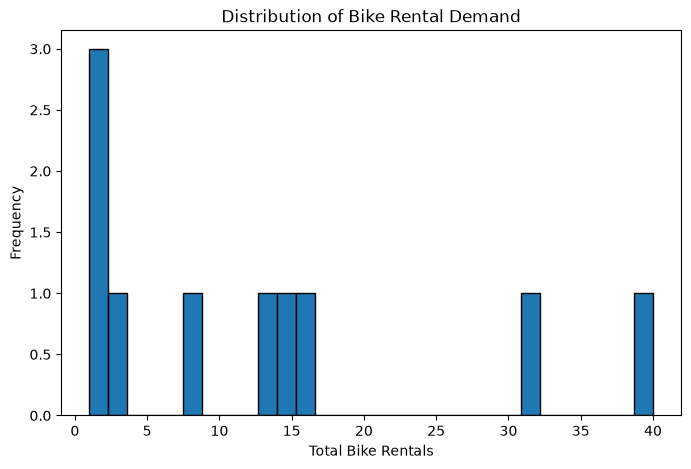

In [5]:

plt.figure(figsize=(8, 5))
plt.hist(df["cnt"], bins=30, edgecolor="black")
plt.xlabel("Total Bike Rentals")
plt.ylabel("Frequency")
plt.title("Distribution of Bike Rental Demand")
plt.show()


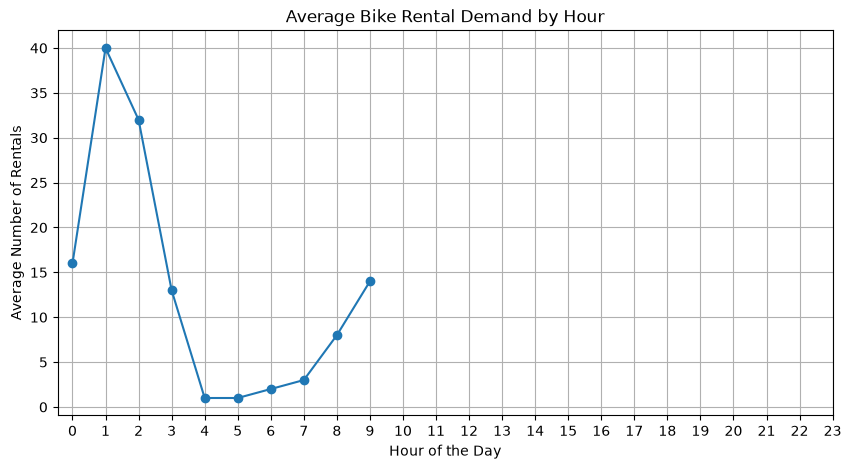

In [6]:

hourly_demand = df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 5))
plt.plot(hourly_demand.index, hourly_demand.values, marker="o")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")
plt.title("Average Bike Rental Demand by Hour")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()


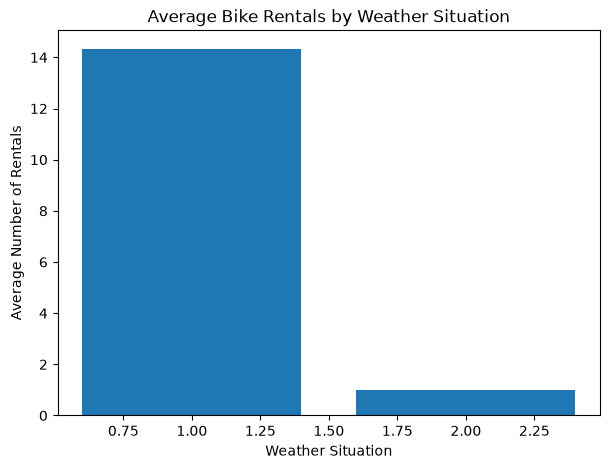

In [7]:

weather_demand = df.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(7, 5))
plt.bar(weather_demand.index, weather_demand.values)
plt.xlabel("Weather Situation")
plt.ylabel("Average Number of Rentals")
plt.title("Average Bike Rentals by Weather Situation")
plt.show()



## 6. Data Preprocessing

The target variable is `cnt`, which represents the total number of rented bikes.

We remove `instant` because it is a record index, and `dteday` because the date information is already partly represented by other columns.

We also remove `casual` and `registered` because their sum equals the target variable `cnt`. Keeping them would cause target leakage.

The remaining features are used to predict bike rental demand.


In [8]:

X = df.drop(
    columns=["cnt", "casual", "registered", "instant", "dteday"],
    errors="ignore"
)

y = df["cnt"]

print("Input features:")
print(X.columns.tolist())

print("\nNumber of input features:", X.shape[1])
print("Target variable: cnt")


Input features:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed']

Number of input features: 12
Target variable: cnt



## 7. Splitting the Dataset

We split the dataset into training and testing sets.

- Training set: 80% of the data
- Testing set: 20% of the data
- `random_state=42` ensures reproducible results.

The training data is used to fit the models, while the testing data is used to evaluate their performance on unseen observations.


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (8, 12)
Testing features: (2, 12)
Training target: (8,)
Testing target: (2,)



## 8. Model Training

We train four regression algorithms:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor
4. Gradient Boosting Regressor

These models learn the relationship between the input features and the number of bikes rented.


In [10]:

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=15
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = model

    print(name, "trained successfully!")


Linear Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
Gradient Boosting trained successfully!



## 9. Model Evaluation

We evaluate the models using four regression metrics:

- **MAE (Mean Absolute Error):** Average absolute difference between actual and predicted values. Lower is better.
- **MSE (Mean Squared Error):** Average squared prediction error. Lower is better.
- **RMSE (Root Mean Squared Error):** Square root of MSE, expressed in the target variable's units. Lower is better.
- **R² Score:** Measures how much variation in the target is explained by the model. A score closer to 1 generally indicates a better fit.


In [11]:

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="RMSE")

display(results_df.round(3))


,Model,MAE,MSE,RMSE,R2 Score
1,Decision Tree,7.500,56.500,7.517,0.779
3,Gradient Boosting,9.219,98.777,9.939,0.614
2,Random Forest,9.835,141.684,11.903,0.447
0,Linear Regression,14.346,206.254,14.362,0.194



## 10. Comparing Regression Models

We compare the RMSE values of all four models to understand which model produces lower prediction errors on the test dataset.


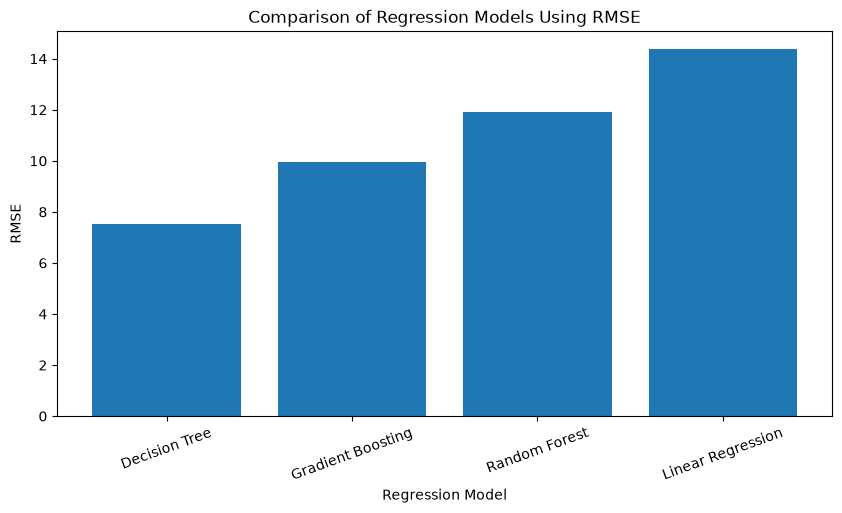

In [12]:

plt.figure(figsize=(10, 5))

plt.bar(results_df["Model"], results_df["RMSE"])

plt.xlabel("Regression Model")
plt.ylabel("RMSE")
plt.title("Comparison of Regression Models Using RMSE")
plt.xticks(rotation=20)
plt.show()



## 11. Best Model Selection

The model with the lowest RMSE is selected as the best-performing model among the four models evaluated on the test dataset.

We compare actual bike rental counts with predicted counts to visualize the model's prediction performance.


Best Model: Decision Tree
MAE: 7.5
MSE: 56.5
RMSE: 7.517
R2 Score: 0.779


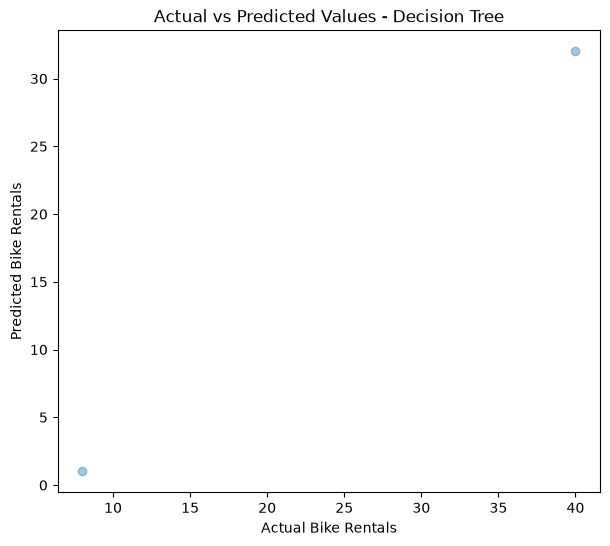

In [13]:

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("MAE:", round(mean_absolute_error(y_test, y_pred_best), 3))
print("MSE:", round(mean_squared_error(y_test, y_pred_best), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred_best)), 3))
print("R2 Score:", round(r2_score(y_test, y_pred_best), 3))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_best, alpha=0.4)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title(f"Actual vs Predicted Values - {best_model_name}")

plt.show()



## 12. Feature Importance

Feature importance helps identify which input features contribute most to predictions. Tree-based models such as Decision Tree and Random Forest provide feature importance values.


,Feature,Importance
3,hr,0.841062
10,hum,0.158938
1,yr,0.000000
0,season,0.000000
2,mnth,0.000000
4,holiday,0.000000
6,workingday,0.000000
5,weekday,0.000000
7,weathersit,0.000000
8,temp,0.000000


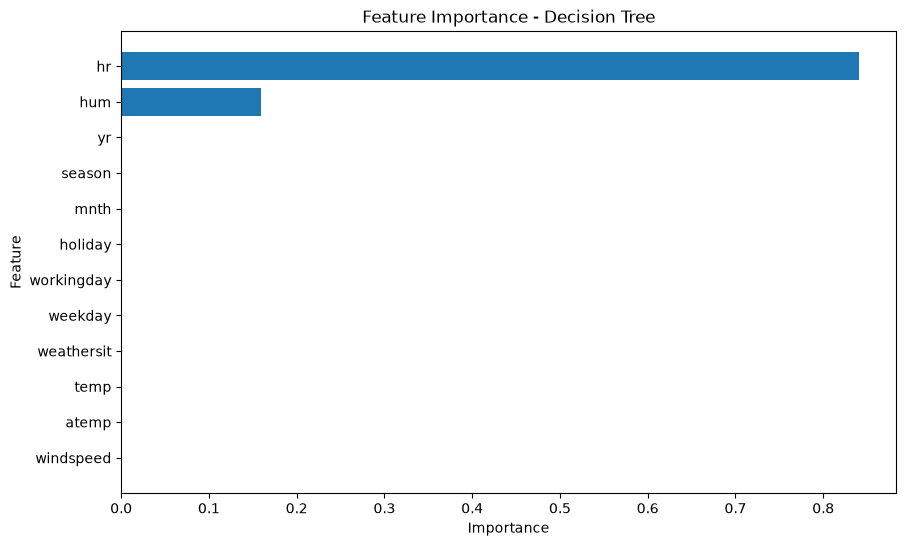

In [14]:

if hasattr(best_model, "feature_importances_"):

    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": best_model.feature_importances_
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    )

    display(importance_df)

    plt.figure(figsize=(10, 6))
    plt.barh(
        importance_df["Feature"],
        importance_df["Importance"]
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title(f"Feature Importance - {best_model_name}")
    plt.gca().invert_yaxis()
    plt.show()

else:
    print(
        "The selected model does not provide built-in "
        "feature importance values."
    )



## 13. Sample Predictions

We display a few actual and predicted bike rental counts to inspect the model's predictions.


In [15]:

comparison = pd.DataFrame({
    "Actual Rentals": y_test.iloc[:10].values,
    "Predicted Rentals": np.round(y_pred_best[:10], 2)
})

display(comparison)


,Actual Rentals,Predicted Rentals
0,8,1.0
1,40,32.0



## 14. Conclusion

In this project, we developed a machine learning regression system to predict hourly bike rental demand using the UCI Bike Sharing Dataset.

We performed data inspection, exploratory data analysis, preprocessing, train-test splitting, model training, and evaluation.

Four regression algorithms were compared: Linear Regression, Decision Tree, Random Forest, and Gradient Boosting.

The best-performing model was selected based on its RMSE on the test dataset. The evaluation metrics and feature importance analysis helped us understand prediction accuracy and the factors associated with bike rental demand.

This project demonstrates how machine learning can support demand forecasting and resource planning in bike-sharing systems.



## References

Fanaee-T, H., & Gama, J. (2013). *Bike Sharing Dataset*. UCI Machine Learning Repository.

Dataset link: https://archive.ics.uci.edu/dataset/275/bike+sharing

The dataset contains hourly and daily bike rental counts with corresponding seasonal and weather information.
